# *Segmentación de paises mediante aprendizaje no supervisado.*

- Este proyecto se desarrolla como actividad NF3 para la asignatura de *Sistemas de aprendizaje automatico*.
- El objetivo de este proyecto, es segmentar paises segun patrones y similitudes entre sus datos, se utilizara un modelo de aprendizaje no supervisado el cual se encargara de crear diferentes agrupaciones o *clusters*.

## *Aplicación práctica.*

- La agrupación de países según sus indicadores socioeconómicos puede servir para identificar países con perfiles similares y utilizarlos como referencia al comparar indicadores de salud, economía o comercio. Por ejemplo, permite detectar qué países destacan por su actividad comercial en relación con su PIB y estudiar en qué se diferencian de otros países con ingresos altos.

## *Dataset utilizado.*

- Link Kaggle: [Unsupervised-Learning-On-Country-Data](https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data)

## *Descripción de las variables*

La información se ha obtenido del archivo `data-dictionary.csv`, proporcionado por el creador del dataset.

| Variable | Descripción |
|---|---|
| `country` | Nombre del país. |
| `child_mort` | Muertes de menores de cinco años por cada 1.000 nacidos vivos. |
| `exports` | Exportaciones per cápita como porcentaje del PIB per cápita. |
| `health` | Gasto sanitario per cápita como porcentaje del PIB per cápita. |
| `imports` | Importaciones per cápita como porcentaje del PIB per cápita. |
| `income` | Ingreso neto por persona. |
| `inflation` | Indicador denominado inflación, cuya descripción es ambigua. |
| `life_expec` | Esperanza de vida al nacer, en años. |
| `total_fer` | Tasa estimada de hijos por mujer. |
| `gdpp` | PIB por habitante. |

Para el entrenamiento se utilizarán las variables numéricas, excepto `inflation`, ya que no se ha podido confirmar qué mide exactamente. La columna `country` se conservará para identificar los países en los resultados.

Las unidades y el periodo de algunos indicadores, como `income` y `gdpp`, deben confirmarse en la fuente original.

### *Librerias usadas en el proyecto*

- Pandas 
- Seaborn
- Matplotlib
- ScikitLearn


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

df = pd.read_csv('archive/Country-data.csv')

print(df.describe())

       child_mort     exports      health     imports         income  \
count  167.000000  167.000000  167.000000  167.000000     167.000000   
mean    38.270060   41.108976    6.815689   46.890215   17144.688623   
std     40.328931   27.412010    2.746837   24.209589   19278.067698   
min      2.600000    0.109000    1.810000    0.065900     609.000000   
25%      8.250000   23.800000    4.920000   30.200000    3355.000000   
50%     19.300000   35.000000    6.320000   43.300000    9960.000000   
75%     62.100000   51.350000    8.600000   58.750000   22800.000000   
max    208.000000  200.000000   17.900000  174.000000  125000.000000   

        inflation  life_expec   total_fer           gdpp  
count  167.000000  167.000000  167.000000     167.000000  
mean     7.781832   70.555689    2.947964   12964.155689  
std     10.570704    8.893172    1.513848   18328.704809  
min     -4.210000   32.100000    1.150000     231.000000  
25%      1.810000   65.300000    1.795000    1330.000000

### *EDA*

- Registros : 167 registros.

- Columnas / Variables : 10 columnas.

- Valores nulos : El dataset esta bastante limpio y cuenta con 0 valores nulos entre todas sus variables.

- Valores duplicados : Al igual que con los valores nulos, no contamos con registros duplicados.

- Tipos de datos : Contamos con 7 variables de tipo *float64* **child_mort, exports, health, imports, inflation, life_expec y total_fer** ademas de 1 variable de tipo *str* **country** y 2 variables tipo *int64* **income y gdpp**.

In [2]:
print(f"Registros y columnas del dataset:  {df.shape}\n")
print(f"Valores nulos: \n{df.isna().sum()}\n")
print(f"Numero de registros duplicados: {df.duplicated().sum()} registros.")
print(f"Numero de paises duplicados: {df['country'].duplicated().sum()} paises.")

print(df.info())

Registros y columnas del dataset:  (167, 10)

Valores nulos: 
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Numero de registros duplicados: 0 registros.
Numero de paises duplicados: 0 paises.
<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB
None


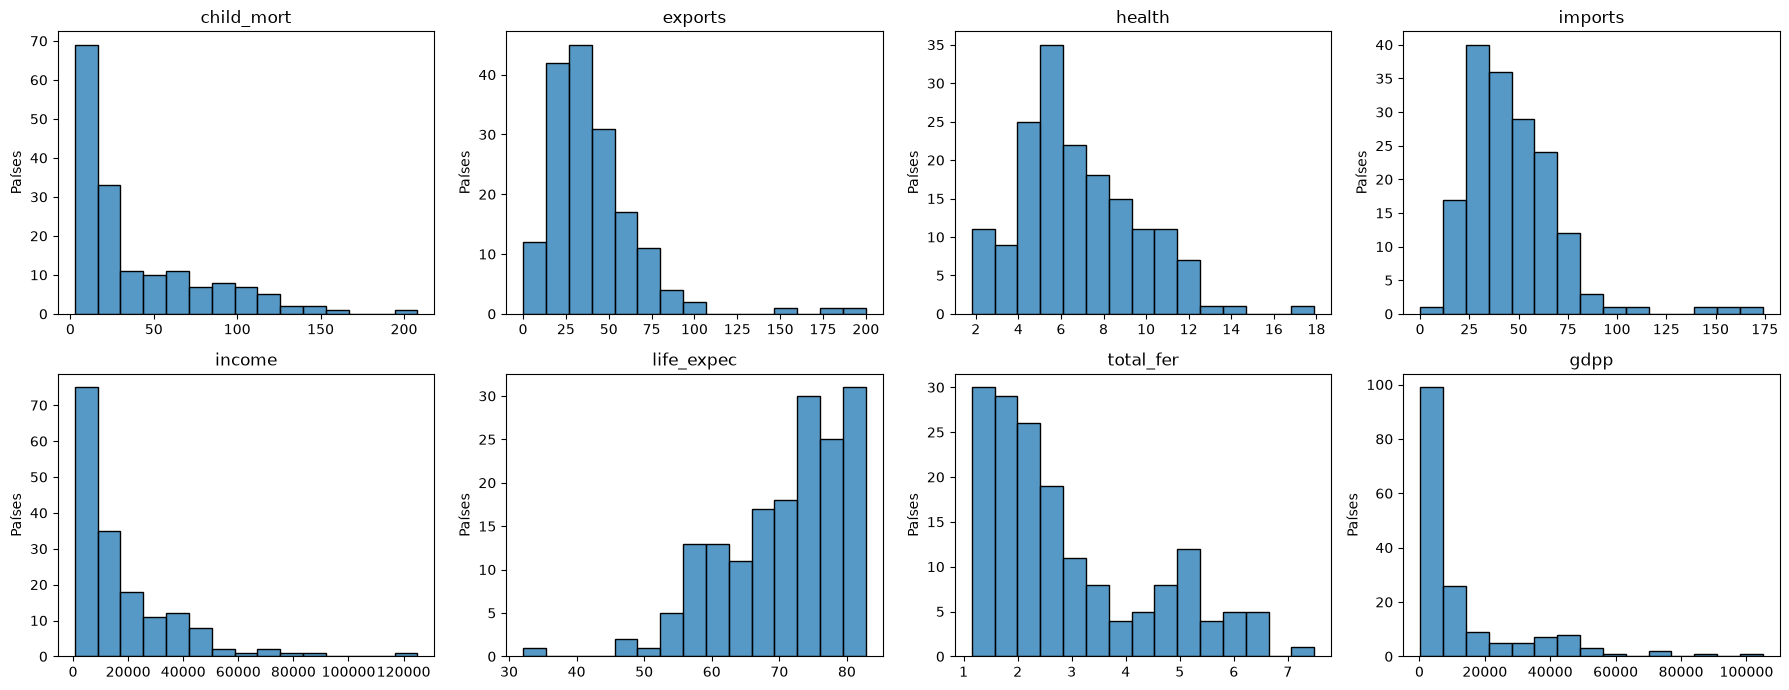

In [3]:
indicadores = df.drop(columns=["country", "inflation"])

fig, ejes = plt.subplots(2, 4, figsize=(18, 7))

for columna, eje in zip(indicadores.columns, ejes.ravel()):
    sns.histplot(data=indicadores, x=columna, bins=15, ax=eje)
    eje.set_title(columna)
    eje.set(xlabel="", ylabel="Países")

plt.tight_layout()
plt.show()

- child_mort : Distribucion asimetrica hacia la derecha, la frecuencia es mayor en los primeros intervalos y baja con rapidez, hay una cola hacia valores altos y un valor separado en torno a 200.

- exports : Distribucion asimetrica hacia la derecha, el intervalo mas frecuente de paises se encuentra entre 0-100 , de ahi baja sustancialmente con valores separados entorno a 150 y 200.

- health : Distribucion asimetrica hacia la derecha, la frecuencia es mayor entre 3-10, bajando en general desde los 5-6, valores separados entorno a 18.

- imports : Distribucion asimetrica hacia la derecha, la frecuencia es mayor en el intervalo de 10-80 con el maximo numero de paises entorno a 25, presenta valores separados sobre 150.

- income : Distribucion asimetrica hacia la derecha, el mayor numero de paises se concentra en el primer intervalo, de ahi baja con ciertos repuntes y con valores separados entorno a 120,000.

- life_expec : Distribucion asimetrica hacia la izquierda, las barras mas altas se encuentran en el intervalo de 75-85, se obsevan valores separados en el primer intervalo y de ahi, una subida substancial hasta la mayoria.

- total_fer : Distribucion asimetrica hacia la derecha, el grupo mayoritario se encuentra sobre 1-3, aunque la cola esta a la derecha, vemos como entorno a 5, se produce una pequenia subida.

- gdpp : Distribucion asimetrica hacia la derecha, la mayoria se encuentra al principio del primer intervalo, con una bajada substancial y con valores externos en el intervalo final.

### *Conclusión EDA*

El conjunto contiene 167 países y no presenta valores nulos ni registros duplicados, por lo que no fue necesario imputar valores ni eliminar filas por estos motivos. En los histogramas se observan valores extremos, especialmente en variables como exports, imports, income y gdpp. Decidí conservarlos porque un valor poco frecuente puede reflejar una característica relevante del país y no es, evidencia de un error. Más adelante comprobé que Luxemburgo, Malta y Singapur forman un grupo con valores especialmente altos de exportaciones e importaciones en relación con su PIB.

*Los 10 paises con el PIB per capita mas alto*

In [4]:
df.nlargest(10, "gdpp")[["country", "gdpp", "income"]]

,country,gdpp,income
91,Luxembourg,105000,91700
114,Norway,87800,62300
145,Switzerland,74600,55500
123,Qatar,70300,125000
44,Denmark,58000,44000
144,Sweden,52100,42900
7,Australia,51900,41400
110,Netherlands,50300,45500
73,Ireland,48700,45700
159,United States,48400,49400


*Los 10 paises con el Ingreso medio por persona, mas alto*

In [5]:
df.nlargest(10,"income")[['country','income','gdpp']]

,country,income,gdpp
123,Qatar,125000,70300
91,Luxembourg,91700,105000
23,Brunei,80600,35300
82,Kuwait,75200,38500
133,Singapore,72100,46600
114,Norway,62300,87800
157,United Arab Emirates,57600,35000
145,Switzerland,55500,74600
159,United States,49400,48400
73,Ireland,45700,48700


***Observaciones:*** Luxemburgo presenta el mayor PIB por habitante del conjunto de datos (gdpp = 105.000). Sin embargo, el orden por PIB por habitante no coincide necesariamente con el orden por ingreso neto por persona. Por ejemplo, Catar ocupa el cuarto lugar en gdpp, con 70.300, pero tiene el valor de income más alto, con 125.000. Esto demuestra que ambos indicadores recogen aspectos económicos distintos: uno mide la producción por habitante y el otro, el ingreso neto por persona.

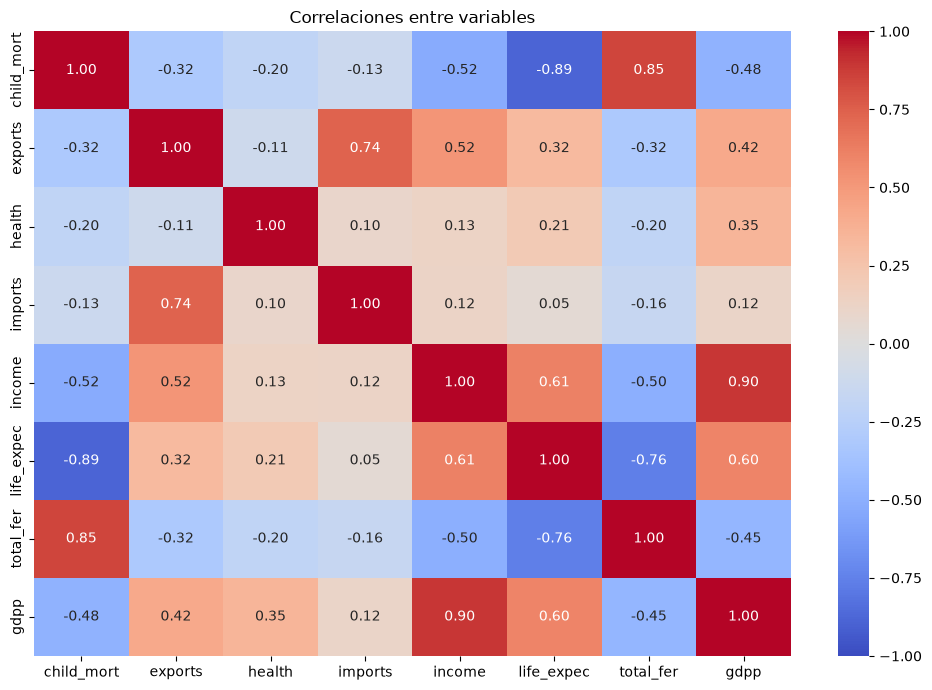

In [6]:
indicadores = df.drop(columns=["country", "inflation"])

plt.figure(figsize=(10, 7))
sns.heatmap(
    indicadores.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlaciones entre variables")
plt.tight_layout()
plt.show()

***Correlaciones entre variables.*** 
- Las correlaciones positivas más destacadas son las de income con gdpp (0,90) y child_mort con total_fer (0,85). También se observan relaciones negativas fuertes entre child_mort y life_expec (−0,89), y entre total_fer y life_expec (−0,76).

***Decisión para el clustering.*** 
- Compararé una versión con los ocho indicadores seleccionados y otra sin income ni total_fer. Mi teoria es que estas dos variables aportan parte de la información que ya recogen otros indicadores y que, al incluirlas juntas, ciertos patrones económicos y demográficos podrían pesar más en el cálculo de las distancias y ser redundantes. La correlación por sí sola no demuestra que eliminar esas variables sea mejor. Por eso, se eligira el entrenamiento que mejor reendimiento obtenga.

### *Selección del modelo y preparación de datos*
El problema es de agrupamiento no supervisado, ya que el conjunto no contiene etiquetas que indiquen a qué grupo pertenece cada país. Entre las alternativas están el clustering jerárquico, que permite explorar agrupaciones a distintos niveles, y DBSCAN, que identifica grupos por densidad y puede dejar observaciones como ruido. Elegí K-means porque los indicadores son numéricos y el objetivo es asignar los países a grupos cuyos perfiles puedan compararse de forma sencilla.

Excluí country del entrenamiento porque solo identifica a cada país, e inflation porque la descripción del diccionario no permite saber con claridad qué mide. Comparé una versión con ocho indicadores y otra con seis, sin income ni total_fer. Apliqué StandardScaler en ambas versiones para que las diferencias de escala entre indicadores no influyeran el cálculo de distancias. Utilicé los 167 registros para el entrenamiento y evalué los grupos mediante la silueta.

In [7]:
X = df.drop(columns=['country','inflation'])
X_reduced = X.drop(columns=['income','total_fer']) # Datos sin las variables income y total_fer

X_scaled = StandardScaler().fit_transform(X)
X_reduced_scaled = StandardScaler().fit_transform(X_reduced)

### *Selección de k*

In [8]:
print("--- Modelo completo ---")    

for i in range(2,7):
    test_model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    
    tags = test_model.fit_predict(X_scaled)
    silhouette = silhouette_score(X_scaled, tags)
    print(f"k={i} > silueta={silhouette}")
    
print("\n--- Modelo reducido ---")    

for i in range(2,7):
    test_model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )
    
    tags = test_model.fit_predict(X_reduced_scaled)
    silhouette = silhouette_score(X_reduced_scaled, tags)
    print(f"k={i} > silueta={silhouette}")

--- Modelo completo ---
k=2 > silueta=0.30349127565150674
k=3 > silueta=0.3137787465860659
k=4 > silueta=0.3335568917629348
k=5 > silueta=0.2455285944928488
k=6 > silueta=0.23614761241698168

--- Modelo reducido ---
k=2 > silueta=0.28077612883409053
k=3 > silueta=0.3040656549136184
k=4 > silueta=0.31671054487411116
k=5 > silueta=0.2583599499452913
k=6 > silueta=0.27101350190613216


### *Resultado de la selección de k*

Probé de dos a seis clústeres. `k=4` obtuvo la mayor silueta en ambos conjuntos de variables: 0,334 en el completo y 0,317 en el reducido. La mejora respecto a `k=3` fue pequeña, pero la solución de cuatro grupos permitió distinguir un perfil comercial que no aparecía como grupo separado con tres. Mantuve `k=4` en ambos modelos para comparar el efecto de retirar dos indicadores sin cambiar el número de grupos

### Entrenamiento de los modelos 

In [9]:
k = 4 # resultado de la selecion anterior

model = KMeans(n_clusters=k, random_state=42, n_init=10)
model_reduced = KMeans(n_clusters=k, random_state=42, n_init=10)

clusters = model.fit_predict(X_scaled)
clusters_reduced = model_reduced.fit_predict(X_reduced_scaled)

### Paises en cada cluster

In [10]:
results = df[['country']].copy()

results['clusters'] = clusters
results['reduced_clusters'] = clusters_reduced

results.head(10)

,country,clusters,reduced_clusters
0,Afghanistan,3,0
1,Albania,0,2
2,Algeria,0,2
3,Angola,3,0
4,Antigua and Barbuda,0,2
5,Argentina,0,2
6,Armenia,0,2
7,Australia,2,1
8,Austria,2,1
9,Azerbaijan,0,2


In [11]:
print(f"Paises en cada cluster (modelo con todas las variables)\n{results['clusters'].value_counts().sort_index()}\n")
print(f"Paises en cada cluster (modelo reducido)\n{results['reduced_clusters'].value_counts().sort_index()}")

Paises en cada cluster (modelo con todas las variables)
clusters
0    89
1     3
2    30
3    45
Name: count, dtype: int64

Paises en cada cluster (modelo reducido)
reduced_clusters
0    48
1    26
2    90
3     3
Name: count, dtype: int64


In [12]:
pd.crosstab(results["clusters"], results["reduced_clusters"])

reduced_clusters,0,1,2,3
clusters,,,,
0,3,1,85,0
1,0,0,0,3
2,0,25,5,0
3,45,0,0,0


In [13]:
# Cluster del modelo reducido - Cluster del modelo completo
equivalencias = {2: 0, 3: 1, 1: 2, 0: 3}
results["reduced_alineado"] = results["reduced_clusters"].map(equivalencias)

coinciden = results["clusters"] == results["reduced_alineado"]

results_len = len(results)

print(f"Coinciden: {coinciden.sum()}/{results_len} ({coinciden.mean():.2%})")
print(f"No coinciden: {(~coinciden).sum()}/{results_len} ({(~coinciden).mean():.2%})")

Coinciden: 158/167 (94.61%)
No coinciden: 9/167 (5.39%)


### Comparación de las asignaciones entre modelos

Al comparar directamente las etiquetas de ambos modelos con `k=4`, el **95,21 %** de los países tiene un número de clúster distinto. Sin embargo, K-means asigna esas etiquetas de forma aleatoria. Por ejemplo, los **45 países del clúster 3** del modelo completo aparecen juntos en el **clúster 0** del reducido. Aunque cambia el número, esos países siguen agrupados entre sí.

Al emparejar los clústeres según los países que comparten (`0 - 2`, `1 - 3`, `2 - 1` y `3 - 0`), se observa que **158 de los 167 países (94,61 %) mantienen su asignación**. Los **9 restantes (5,39 %)** sí quedan en un grupo diferente tras el emparejamiento.

In [14]:
print("Paises del cluster 1 modelo completo")
c1 = results.loc[results['clusters']==1]
df_c1 = df.loc[df['country'].isin(c1['country'])]
display(df_c1)

print("Paises del cluster 3 modelo reducido")
c3 = results.loc[results['reduced_clusters']==3]
df_c3 = df.loc[df['country'].isin(c3['country'])]

display(df_c3)


Paises del cluster 1 modelo completo


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


Paises del cluster 3 modelo reducido


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


### Perfil comercial del clúster de tres países

Con `k=4`, los mismos tres países forman un grupo propio en ambos modelos: el clúster `1` del modelo completo y el `3` del reducido. Aunque tienen ingresos altos, lo que más destaca al comparar sus perfiles son **`exports` e `imports`**. En el modelo completo, la mediana de `exports` es **175**, frente a **44,25** en el otro clúster de ingresos altos. En `imports`, la mediana es **154**, frente a **35**.

Estos valores apuntan a un **perfil comercial atípico**: las exportaciones y las importaciones representan una proporción del PIB mucho mayor en este grupo. La solución con cuatro clústeres permite distinguir ese perfil específico. Que el grupo sea pequeño no implica que sus datos sean erróneos ni que deban excluirse del análisis.

In [15]:
# Medianas de los indicadores en sus unidades originales
perfil_completo = (
    df.assign(cluster=clusters)
    .groupby("cluster")[X.columns]
    .median()
    .round(2)
)

perfil_reducido = (
    df.assign(cluster=clusters_reduced)
    .groupby("cluster")[X.columns]
    .median()
    .round(2)
)

print("Modelo completo")
display(perfil_completo)

print("Modelo reducido")
display(perfil_reducido)

Modelo completo


,child_mort,exports,health,imports,income,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,18.1,38.40,6.00,49.2,10900.0,73.7,2.23,5020.0
1,2.8,175.00,7.77,154.0,72100.0,81.3,1.36,46600.0
2,4.2,44.25,9.54,35.0,40550.0,80.4,1.87,41850.0
3,90.3,23.80,5.30,40.3,1850.0,59.5,5.11,769.0


Modelo reducido


,child_mort,exports,health,imports,income,life_expec,total_fer,gdpp
cluster,,,,,,,,
0,89.75,23.30,5.26,39.75,1900.0,59.80,5.06,932.0
1,4.20,36.85,9.87,33.95,40100.0,80.60,1.87,44450.0
2,17.30,39.65,5.98,49.40,11300.0,74.05,2.17,5430.0
3,2.80,175.00,7.77,154.00,72100.0,81.30,1.36,46600.0


### Comparación de los perfiles de los clústeres

Después de emparejar los clústeres de ambos modelos según los países que comparten, comparé las medianas de sus indicadores en las unidades originales. Aunque los números de los clústeres cambian, los cuatro perfiles generales se mantienen:

| Modelo completo - reducido | Perfil observado |
|---|---|
| **0 - 2** | Perfil intermedio. La mediana de esperanza de vida pasa de **73,7 a 74,05 años** y la del PIB por habitante, de **5.020 a 5.430**. |
| **1 - 3** | Perfil comercial atípico. Está formado por los mismos tres países en ambos modelos, por lo que sus medianas coinciden. Destacan las exportaciones (**175**) y las importaciones (**154**). |
| **2 - 1** | Perfil de ingresos altos, con baja mortalidad infantil y una esperanza de vida cercana a **80 años**. La esperanza de vida apenas cambia, pero la mediana de exportaciones baja de **44,25 a 36,85**. |
| **3 - 0** | Perfil con mayor mortalidad infantil y fecundidad, y con la menor esperanza de vida. La mediana de fecundidad se mantiene cerca de **5 hijos por mujer** en ambos modelos. |

En conjunto, al quitar `income` y `total_fer` del entrenamiento se conservan las principales diferencias entre los grupos. Por ejemplo, el grupo con mayor fecundidad sigue destacando en ese indicador aunque el modelo reducido no lo utilizó para agrupar los países. También cambian algunas medianas, como la de exportaciones en el grupo de ingresos altos. Esto indica que la versión reducida conserva los perfiles generales, aunque no reproduce exactamente la agrupación del modelo completo.

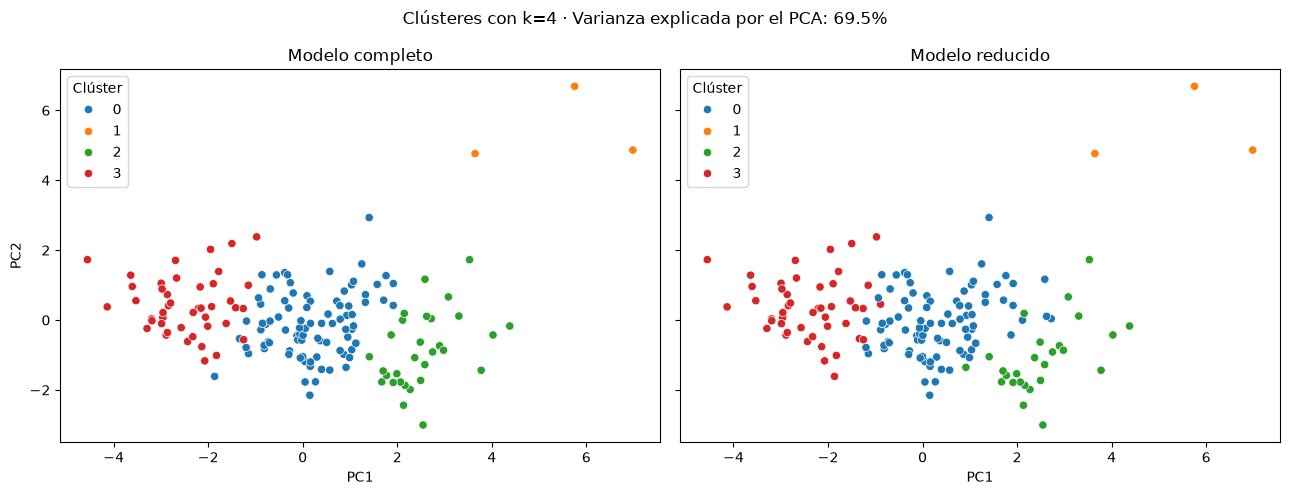

In [16]:


# Mismos ejes para comparar los dos modelos
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_scaled)

grafico = results.copy()
grafico["PC1"] = coordenadas[:, 0]
grafico["PC2"] = coordenadas[:, 1]

# Etiqueta del modelo reducido - etiqueta del modelo completo.
equivalencias = {2: 0, 3: 1, 1: 2, 0: 3}
grafico["reduced_alineado"] = grafico["reduced_clusters"].map(equivalencias)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for eje, columna, titulo in zip(
    ejes,
    ["clusters", "reduced_alineado"],
    ["Modelo completo", "Modelo reducido"]
):
    sns.scatterplot(
        data=grafico,
        x="PC1",
        y="PC2",
        hue=columna,
        hue_order=[0, 1, 2, 3],
        palette="tab10",
        ax=eje
    )
    eje.set_title(titulo)
    eje.legend(title="Clúster")

varianza = pca.explained_variance_ratio_.sum()
fig.suptitle(f"Clústeres con k=4 · Varianza explicada por el PCA: {varianza:.1%}")
plt.tight_layout()
plt.show()

Los dos gráficos utilizan la misma proyección PCA, calculada sobre los ocho indicadores estandarizados. Los dos primeros componentes explican el 69,5 % de la varianza de esos datos. Cada país ocupa la misma posición en las dos gráficas y los colores representan clústeres emparejados, de modo que un cambio de color indica una asignación distinta.

Los tres países del grupo comercial destacan en la parte superior derecha en ambos gráficos. Los otros grupos se distribuyen principalmente de izquierda a derecha, con cierto solapamiento alrededor del grupo intermedio. El PCA se utiliza para visualizar las agrupaciones: K-means se ajustó con los indicadores estandarizados de cada versión, antes de proyectarlos en dos dimensiones.

### Conclusión

El modelo final elegido es K-means con cuatro clústeres y seis indicadores estandarizados: child_mort, exports, health, imports, life_expec y gdpp. Elegí esta versión porque, pese a obtener una silueta algo menor que el modelo completo, conserva los perfiles generales y coincide con él en la asignación del 94,61 % de los países tras emparejar los clústeres. Así, es posible describir agrupaciones similares utilizando dos indicadores menos.

La segmentación distingue un perfil intermedio, un perfil con ingresos altos y baja mortalidad infantil, otro con mayor mortalidad infantil y menor esperanza de vida, y un grupo de tres países con una actividad comercial especialmente elevada en relación con su PIB. Estos grupos dependen de los indicadores elegidos y del escalado, por lo que deben interpretarse como perfiles descriptivos del conjunto analizado.

Como mejora, probaría el clustering jerárquico con los mismos indicadores estandarizados para comprobar si Luxemburgo, Malta y Singapur también forman un grupo propio con otro algoritmo. Esto ayudaría a valorar hasta qué punto ese perfil comercial se mantiene al cambiar el método de agrupamiento.